# PFI — Producción anual y diaria de las Reservas 1P de Colombia y regalías esperadas (WTI y Brent)
**Metodología CRISP-DM · Modelos supervisados: árbol de decisión, regresión lineal y red neuronal (más ensambles de árboles)**

Integrantes: Rafael Fajardo Moreno, Sonia Catalina Martinez Herrera y Laura Marcela Garnica Tapia · Octubre de 2026

> **Términos y condiciones.** Los datos son de carácter reservado y tienen un único uso académico, en el marco de la Especialización en Machine
> Learning de la Universidad EAN (2026). Está prohibido el uso, la distribución, la copia o la mejora, total o parcial. Solo se tiene en cuenta el
> pronóstico de desarrollo de reservas del IRR 2024, sin contemplar la migración de reservas 2P y 3P ni la evolución de recursos contingentes.
> Los nombres de campos y contratos están anonimizados (Campo_001…, Contrato_001…). El aplicativo pide contraseña: solicitarla a
> rafajard53009@universidadean.edu.co.

**Pregunta:** ¿cómo se comporta la producción anual y diaria de las Reservas 1P de Colombia y cuánto se espera recibir por regalías cada año,
según los indicadores de referencia WTI y Brent?

**Reproducibilidad:** reiniciar el núcleo y ejecutar todo desde la carpeta del proyecto (contiene `datos_crudos/`); en Google Colab, la celda del paso 0 pide subir los datos. Semilla 42; versiones en la
primera celda. Genera `artefactos/` (que usa el aplicativo) y `ficha_datos.md`. Tiempo aproximado: 3 a 5 minutos.

**Paso 0 · Datos.** En el computador local no hace nada (los datos ya están en `datos_crudos/`). En **Google Colab**, al ejecutar esta celda
aparece un botón *Elegir archivos*: suba **PFI_entrega.zip** (o el Excel y el CSV de precios de `datos_crudos/`) y la celda los deja en su lugar.
Alternativa: montar Google Drive y cambiar de carpeta con `%cd` a la del proyecto antes de ejecutar.

In [1]:
# ---- Paso 0: dejar los datos en datos_crudos/ (en Google Colab se suben aquí; en el computador local ya están)
import sys, zipfile, shutil
from pathlib import Path

DATOS = Path.cwd() / "datos_crudos"
NECESARIOS = {".xlsx": "1_ML_OIL_produccion_reservas.xlsx", ".csv": "precios_brent_wti_mensual_EIA.csv"}

def faltantes():
    return [n for n in NECESARIOS.values() if not (DATOS / n).exists()]

def guardar(nombre, contenido):
    """Guarda un archivo subido con el nombre que espera el cuaderno (Colab renombra repetidos: 'archivo (1).xlsx')."""
    ext = Path(nombre).suffix.lower()
    if ext in NECESARIOS:
        DATOS.mkdir(exist_ok=True)
        (DATOS / NECESARIOS[ext]).write_bytes(contenido)

if faltantes() and "google.colab" in sys.modules:
    from google.colab import files
    print("Suba PFI_entrega.zip, o los dos archivos de datos_crudos/:", ", ".join(faltantes()))
    for nombre, contenido in files.upload().items():
        if nombre.lower().endswith(".zip"):
            with zipfile.ZipFile(nombre) as z:
                for m in z.namelist():
                    if Path(m).name in NECESARIOS.values():
                        guardar(Path(m).name, z.read(m))
        else:
            guardar(nombre, contenido)

if faltantes():
    raise FileNotFoundError(f"Faltan en {DATOS}: {faltantes()}. En Colab, ejecute de nuevo esta celda y suba PFI_entrega.zip "
                            "(o el Excel y el CSV de precios). En el computador, ejecute el cuaderno desde la carpeta del proyecto.")
print("Datos listos en", DATOS, "→", sorted(p.name for p in DATOS.iterdir()))

Datos listos en /home/claude/PFI_R1P_Regalias/datos_crudos → ['1_ML_OIL_produccion_reservas.xlsx', 'precios_brent_wti_mensual_EIA.csv']


In [2]:
import json, platform, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42                                   # semilla única para todo el cuaderno
np.random.seed(SEED)

BASE = Path.cwd()                           # ejecutar desde la carpeta del proyecto (contiene datos_crudos/)
CRUDOS, ART = BASE / "datos_crudos", BASE / "artefactos"
FIG = ART / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
EXCEL = CRUDOS / "1_ML_OIL_produccion_reservas.xlsx"

VERSIONES = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
             "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "semilla": SEED}
print(VERSIONES)

# Convención de días del archivo fuente (columna "Producción Dia Bls"): 2024 bisiesto, 2026 = enero-junio (181 días)
DIAS_FUENTE = {2023: 365, 2024: 366, 2025: 365, 2026: 181}
def dias(anio):
    """Días para convertir barriles anuales en barriles por día (2027+ = 365, como en el archivo fuente)."""
    return DIAS_FUENTE.get(anio, 365)

# Paleta de www.rafaelfajardomoreno.com y fuente Arial Narrow (si no está instalada se usa una equivalente)
NAVY, GOLD, STONE, NIGHT, GOLD_LT, CREAM = "#1F3251", "#C8973A", "#6B7785", "#0F1923", "#DEB86A", "#F7F5F0"
AZUL, NARANJA, GRIS = NAVY, GOLD, STONE
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
from cycler import cycler
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9.5,
                     "font.family": ["Arial Narrow", "PFI Narrow", "Liberation Sans Narrow", "DejaVu Sans"],
                     "axes.prop_cycle": cycler(color=[NAVY, GOLD, STONE, GOLD_LT, "#9AA7B8", NIGHT]),
                     "axes.titlecolor": NIGHT, "axes.labelcolor": NIGHT, "text.color": NIGHT})

{'python': '3.13.16', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'semilla': 42}


## 1. Comprensión del negocio
- **Decisión que se apoya:** programar la producción esperada y el recaudo de regalías por año (presupuesto del Sistema General de Regalías)
  a partir del pronóstico oficial de Reservas Probadas (1P).
- **Quién decide y a quién afecta:** Ministerio de Minas y Energía, ANH y DNP; afecta a departamentos y municipios productores y a las entidades
  que formulan proyectos con regalías.
- **Enfoque:** regresión supervisada de la producción diaria de cada campo (árbol de decisión, regresión lineal, red neuronal y ensambles),
  con la 1P como dato óptimo proyectado y como tope a partir de 2027; regalías con la escala de la Ley 756 de 2002 y precios WTI o Brent.
- **Éxito para el negocio:** error ponderado por barriles (WAPE) por campo menor que el de usar la 1P tal cual y sesgo del total país inferior a ±5%.
- **Alcance:** solo el pronóstico de desarrollo de reservas del IRR 2024; no se modela la migración de reservas 2P y 3P a 1P ni la evolución de
  recursos contingentes.
- **Riesgos:** pocos años observados (2023 a junio de 2026), campos que se unifican o dejan de reportar, choques de precio y orden público.

## 2. Comprensión de los datos
### 2.1 Carga del Excel (cuatro hojas)

In [3]:
# ---- Hoja principal: una fila por campo con atributos, producción real 2023-2026 y Reservas 1P 2024-2060
crudo = pd.read_excel(EXCEL, sheet_name="1P_Oil_final_val_col_abr29 2024")
crudo.columns = [str(c).replace("\n", " ").strip() for c in crudo.columns]
crudo = crudo[crudo["CAMPO"].notna() & ~crudo["CAMPO"].astype(str).str.startswith(("Nota", "Fuente"))].copy()
crudo["CAMPO"] = crudo["CAMPO"].astype(str).str.strip()
ANIOS_REAL = [2023, 2024, 2025, 2026]
ANIOS_1P = sorted(int(c.split()[-1]) for c in crudo.columns if c.startswith("Reservas 1P"))

# ---- Hojas complementarias: pronóstico 1P (operador y contrato), reservas probables (Prb) y posibles (Ps)
def hoja_reservas(nombre):
    h = pd.read_excel(EXCEL, sheet_name=nombre)
    h = h[h["CAMPO"].notna()].copy(); h["CAMPO"] = h["CAMPO"].astype(str).str.strip()
    h.columns = [int(c) if str(c).isdigit() else c for c in h.columns]
    return h
p1 = hoja_reservas("Petróleo_1P Pronóstico"); prb = hoja_reservas("Petróleo_Prb"); ps = hoja_reservas("Petróleo_Ps")

print(f"Hoja principal: {len(crudo)} campos × {crudo.shape[1]} columnas | años reales {ANIOS_REAL} | Reservas 1P {ANIOS_1P[0]}-{ANIOS_1P[-1]}")
print(f"Pronóstico 1P: {p1.CAMPO.nunique()} campos | Probables: {prb.CAMPO.nunique()} | Posibles: {ps.CAMPO.nunique()}")
crudo.iloc[:3, :12]

Hoja principal: 390 campos × 120 columnas | años reales [2023, 2024, 2025, 2026] | Reservas 1P 2024-2060
Pronóstico 1P: 320 campos | Probables: 275 | Posibles: 262


,Cod. Dane Departamento,Departamento,Cod. Dane Municipio,Municipio,Operadora,Tipo Contrato,CAMPO,Producción Bls 2023,Producción Dia Bls 2023,Reservas 1P (bl) 2024,Producción Bls 2024,Producción Dia Bls 2024
0,73.0,TOLIMA,73268.0,ESPINAL,ECOPETROL S.A.,CONVENIOS DE EXPLORACIÓN Y EXPLOTACIÓN,Campo_001,113690.51,311.480849,120400.0000,114325.18,312.363880
1,15.0,BOYACA,15572.0,PUERTO BOYACA,ECOPETROL S.A.,CONTRATOS DE ASOCIACIÓN,Campo_002,683808.29,1873.447370,617742.0000,687346.29,1877.995328
2,85.0,CASANARE,85250.0,PAZ DE ARIPORO,PERENCO COLOMBIA LIMITED,CONTRATOS DE ASOCIACIÓN,Campo_003,483832.31,1325.567973,701889.3798,763201.43,2085.249809


### 2.2 Tablas ordenadas y diagnóstico de calidad

In [4]:
# ---- Tablas ordenadas (formato largo)
ATR = ["Cod. Dane Departamento", "Departamento", "Cod. Dane Municipio", "Municipio", "Operadora", "Tipo Contrato"]
campos = crudo[["CAMPO"] + ATR].rename(columns={"CAMPO": "campo", "Cod. Dane Departamento": "cod_dep", "Departamento": "departamento",
                                                "Cod. Dane Municipio": "cod_mun", "Municipio": "municipio", "Operadora": "operadora",
                                                "Tipo Contrato": "tipo_contrato"})
campos["con_1p"] = campos["campo"].isin(set(p1["CAMPO"]))
# Completar operadora y contrato faltantes desde la hoja del pronóstico 1P
op_p1 = p1.drop_duplicates("CAMPO").set_index("CAMPO")
falt_op = campos["operadora"].isna() & campos["campo"].isin(op_p1.index)
campos.loc[falt_op, "operadora"] = campos.loc[falt_op, "campo"].map(op_p1["OPERADOR"])
campos["contrato"] = campos["campo"].map(op_p1["CONTRATO"])
for c in ["departamento", "municipio", "operadora", "tipo_contrato"]:
    campos[c] = campos[c].fillna("SIN DATO").astype(str).str.strip()
campos["operadora"] = campos["operadora"].str.upper().str.replace(r"[.,]", "", regex=True).str.replace(r"\s+", " ", regex=True)

prod = crudo.melt(id_vars="CAMPO", value_vars=[f"Producción Bls {a}" for a in ANIOS_REAL], var_name="v", value_name="prod_bl")
prod["anio"] = prod["v"].str[-4:].astype(int); prod = prod.drop(columns="v").rename(columns={"CAMPO": "campo"})
prod["bpd"] = prod["prod_bl"] / prod["anio"].map(dias)
r1p = crudo.melt(id_vars="CAMPO", value_vars=[f"Reservas 1P (bl) {a}" for a in ANIOS_1P], var_name="v", value_name="r1p_bl")
r1p["anio"] = r1p["v"].str[-4:].astype(int); r1p = r1p.drop(columns="v").rename(columns={"CAMPO": "campo"})
r1p = r1p[r1p["campo"].isin(campos.loc[campos.con_1p, "campo"])]
def largo(h, col):
    l = h.melt(id_vars="CAMPO", value_vars=[a for a in ANIOS_1P if a in h.columns], var_name="anio", value_name=col)
    return l.rename(columns={"CAMPO": "campo"}).groupby(["campo", "anio"], as_index=False)[col].sum(min_count=1)
r1p = r1p.merge(largo(prb, "prb_bl"), on=["campo", "anio"], how="left").merge(largo(ps, "ps_bl"), on=["campo", "anio"], how="left")
R1P = r1p.pivot(index="campo", columns="anio", values="r1p_bl")
ULT_1P = r1p[r1p.r1p_bl > 0].groupby("campo")["anio"].max()
campos["ultimo_anio_1p"] = campos["campo"].map(ULT_1P)

# ---- Diagnóstico de calidad
falt = crudo[["CAMPO"] + ATR + [f"Producción Bls {a}" for a in ANIOS_REAL] + [f"Reservas 1P (bl) {a}" for a in (2024, 2026, 2030, 2040, 2060)]]
tabla_falt = pd.DataFrame({"tipo": falt.dtypes.astype(str), "faltantes": falt.isna().sum(), "% faltantes": (falt.isna().mean() * 100).round(1)})
tabla_falt.to_csv(ART / "calidad_faltantes.csv")
chk_1p = p1.set_index("CAMPO")[ANIOS_1P].sub(R1P.reindex(p1.CAMPO).values).abs().to_numpy()
pr = prod.merge(r1p[["campo", "anio", "r1p_bl"]], on=["campo", "anio"], how="left")
razon = pr[(pr.anio.isin([2024, 2025])) & (pr.r1p_bl > 0) & (pr.prod_bl > 0)].eval("prod_bl / r1p_bl")
hallazgos = {
    "Campos en la hoja principal": len(campos),
    "Campos con Reservas 1P (presentes en el pronóstico 1P)": int(campos.con_1p.sum()),
    "Campos con producción y sin Reservas 1P": int((~campos.con_1p).sum()),
    "Nombres de campo duplicados": int(campos.campo.duplicated().sum()),
    "Campos 1P sin atributos (completados desde la hoja del pronóstico 1P)": int(falt_op.sum()),
    "Diferencia máxima entre Reservas 1P de la hoja principal y la del pronóstico 1P (bl)": float(np.nanmax(chk_1p)),
    "Valores de producción negativos o cero": int((prod.prod_bl <= 0).sum()),
    "Celdas de producción vacías (campo sin reporte en el año)": int(prod.prod_bl.isna().sum()),
    "Producción 2026 = solo enero-junio (181 días)": "Sí (fórmula de la columna diaria = /181)",
    "Mediana de producción real / Reservas 1P (2024-2025)": round(float(razon.median()), 3),
    "Casos con producción mayor a 2 veces la 1P del año": int((razon > 2).sum()),
    "Producción nacional 2025 / Reservas 1P 2025": round(prod.query("anio==2025").prod_bl.sum() / R1P[2025].sum(), 3),
}
pd.Series(hallazgos, name="valor").to_frame().to_csv(ART / "calidad_hallazgos.csv")
for k, v in hallazgos.items(): print(f"- {k}: {v}")

# ---- Figuras de comprensión de datos
nac = prod.groupby("anio").prod_bl.sum(); nac_bpd = nac / [dias(a) for a in nac.index]
r1p_nac = R1P.sum(); r1p_bpd = r1p_nac / [dias(a) if a != 2026 else 365 for a in r1p_nac.index]
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(nac_bpd.index, nac_bpd / 1e3, color=AZUL, label="Producción real (kbpd; 2026 = ene-jun)")
ax.plot(r1p_bpd.index, r1p_bpd / 1e3, color=NARANJA, marker="o", ms=3, label="Reservas 1P del año (kbpd equivalentes)")
ax.set_xlim(2022.4, 2045); ax.set_ylabel("miles de barriles por día"); ax.legend(fontsize=8)
ax.set_title("Producción real y perfil de Reservas 1P del país")
fig.tight_layout(); fig.savefig(FIG / "nacional_real_vs_1p.png"); plt.close(fig)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].hist(np.log10(prod.query("anio==2025").bpd.dropna()), bins=30, color=AZUL); axs[0].set_title("Tamaño de los campos 2025"); axs[0].set_xlabel("log10(bpd)")
axs[1].hist(razon.clip(0, 3), bins=40, color=NARANJA); axs[1].axvline(1, color="k", lw=1); axs[1].set_title("Producción real / Reservas 1P (2024-2025)"); axs[1].set_xlabel("razón (recortada en 3)")
fig.tight_layout(); fig.savefig(FIG / "distribuciones.png"); plt.close(fig)

- Campos en la hoja principal: 390
- Campos con Reservas 1P (presentes en el pronóstico 1P): 320
- Campos con producción y sin Reservas 1P: 70
- Nombres de campo duplicados: 0
- Campos 1P sin atributos (completados desde la hoja del pronóstico 1P): 5
- Diferencia máxima entre Reservas 1P de la hoja principal y la del pronóstico 1P (bl): 0.0
- Valores de producción negativos o cero: 0
- Celdas de producción vacías (campo sin reporte en el año): 196
- Producción 2026 = solo enero-junio (181 días): Sí (fórmula de la columna diaria = /181)
- Mediana de producción real / Reservas 1P (2024-2025): 0.949
- Casos con producción mayor a 2 veces la 1P del año: 23
- Producción nacional 2025 / Reservas 1P 2025: 1.029


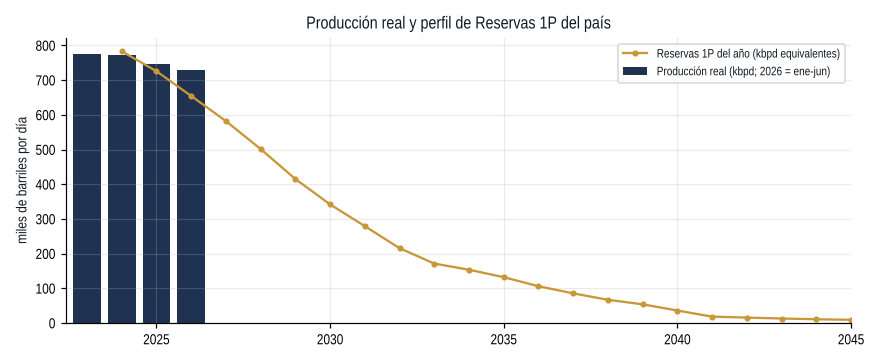

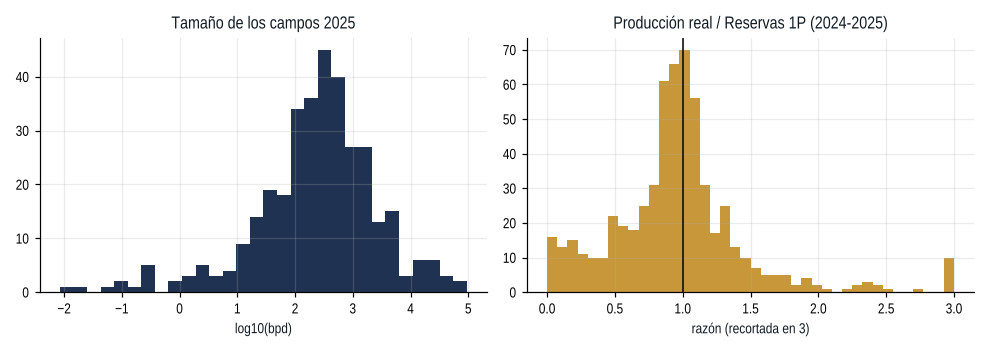

In [5]:
from IPython.display import Image, display
display(Image(filename=str(FIG / "nacional_real_vs_1p.png")))
display(Image(filename=str(FIG / "distribuciones.png")))

### 2.3 Precios de referencia WTI y Brent

In [6]:
# ---- Precios de referencia: promedio anual de los precios mensuales spot (EIA), equivalentes a las series de investing.com
pm = pd.read_csv(CRUDOS / "precios_brent_wti_mensual_EIA.csv")
pa = pm.groupby("anio").agg(brent_usd_bl=("brent_usd_bl", "mean"), wti_usd_bl=("wti_usd_bl", "mean"), meses=("mes", "count")).round(2)
pa["tipo"] = np.where(pa["meses"] == 12, "Observado: promedio de 12 meses", "Observado parcial: promedio enero-septiembre")
DIF = float((pa.loc[2023:2025, "brent_usd_bl"] - pa.loc[2023:2025, "wti_usd_bl"]).mean())     # diferencial Brent-WTI histórico
STEO_BRENT_2027 = 84.0       # EIA, Short-Term Energy Outlook del 6-oct-2026 (Brent promedio 2027)
futuro = pd.DataFrame({"anio": range(2027, 2061)}).set_index("anio")
futuro["brent_usd_bl"] = STEO_BRENT_2027; futuro["wti_usd_bl"] = round(STEO_BRENT_2027 - DIF, 2); futuro["meses"] = 0
futuro["tipo"] = ["Proyección EIA STEO oct-2026 (WTI = Brent − diferencial 2023-2025)" if a == 2027 else
                  "Supuesto: se mantiene el precio de 2027 (editable en el aplicativo)" for a in futuro.index]
precios = pd.concat([pa, futuro]).reset_index().rename(columns={"index": "anio"})
precios.to_csv(ART / "precios_anuales.csv", index=False)
print(f"Diferencial Brent-WTI 2023-2025: {DIF:.2f} USD/bl"); precios.head(6)

Diferencial Brent-WTI 2023-2025: 4.15 USD/bl


,anio,brent_usd_bl,wti_usd_bl,meses,tipo
0,2023,82.47,77.64,12,Observado: promedio de 12 meses
1,2024,80.53,76.55,12,Observado: promedio de 12 meses
2,2025,69.10,65.46,12,Observado: promedio de 12 meses
3,2026,93.27,84.98,9,Observado parcial: promedio enero-septiembre
4,2027,84.00,79.85,0,Proyección EIA STEO oct-2026 (WTI = Brent − di...
5,2028,84.00,79.85,0,Supuesto: se mantiene el precio de 2027 (edita...


## 3. Preparación y diseño experimental (sin fuga)
- **Unidad:** campo × año objetivo t (2024, 2025 y 2026; 2026 = enero-junio, comparable en barriles por día).
- **Objetivo:** cambio logarítmico de la producción diaria frente al año anterior, log(bpd_t / bpd_t-1). Se modela el cambio y no el nivel porque
  el nivel de un campo es muy persistente; la predicción se convierte en barriles por día multiplicando por la producción del año anterior.
- **Variables:** producción del año anterior; Reservas 1P del año, su pendiente y años restantes; reservas probables y posibles; tipo de contrato,
  departamento y operadora. Todas se conocen antes del año objetivo (la 1P, 2P y 3P provienen del IRR 2024, con corte al 31-dic-2023).
- **Sin fuga:** (1) la producción del año objetivo nunca entra como variable; (2) la validación cruzada agrupa por campo (GroupKFold), así un
  mismo campo no está a la vez en entrenamiento y validación; (3) el escalado y la codificación se ajustan dentro del *pipeline*;
  (4) 2026 queda reservado como prueba y se usa una sola vez.
- **Desbalance:** la producción es muy asimétrica; se pondera por la raíz del tamaño del campo y se mide el error en barriles (WAPE).

In [7]:
# ---- Conjunto supervisado: una fila por campo y año objetivo t ∈ {2024, 2025, 2026}
# Objetivo: barriles por día del año t. Variables: solo información conocida antes de t (producción t-1)
# o publicada ex ante (Reservas 1P/2P/3P del IRR con corte 31-dic-2023).
BPD = prod.pivot(index="campo", columns="anio", values="bpd")
R1P_BPD = R1P.apply(lambda s: s / (366 if s.name == 2024 else 365))
PRB = r1p.pivot(index="campo", columns="anio", values="prb_bl").reindex(R1P.index)
PS = r1p.pivot(index="campo", columns="anio", values="ps_bl").reindex(R1P.index)
cat = campos.set_index("campo")
TOP_OP = cat.loc[cat.con_1p, "operadora"].value_counts().head(8).index

def variables(campos_idx, t, bpd_prev):
    """Construye las variables del año t para los campos dados; bpd_prev = producción diaria del año t-1."""
    c = pd.Index(campos_idx)
    r_t = R1P_BPD.reindex(c)[t]; r_n = R1P_BPD.reindex(c).get(t + 1, pd.Series(0, index=c)).fillna(0)
    rest = R1P.reindex(c).loc[:, [a for a in ANIOS_1P if a >= t]].sum(1)
    X = pd.DataFrame(index=c)
    X["log_bpd_previo"] = np.log1p(bpd_prev.reindex(c))
    X["log_1p_anio"] = np.log1p(r_t)
    X["brecha_previo_vs_1p"] = X["log_bpd_previo"] - X["log_1p_anio"]
    X["pendiente_1p"] = np.where(r_t > 0, np.clip(r_n / r_t.where(r_t > 0, 1), 0, 2), 0)
    X["anios_restantes_1p"] = (cat.reindex(c)["ultimo_anio_1p"] - t).clip(lower=0)
    X["reservas_sobre_produccion"] = np.clip(rest / (R1P.reindex(c)[t].where(R1P.reindex(c)[t] > 0)), 0, 40).fillna(0)
    X["log_probables"] = np.log1p(PRB.reindex(c).get(t, pd.Series(0, index=c)).fillna(0) / 365)
    X["log_posibles"] = np.log1p(PS.reindex(c).get(t, pd.Series(0, index=c)).fillna(0) / 365)
    X["tipo_contrato"] = cat.reindex(c)["tipo_contrato"]
    X["departamento"] = cat.reindex(c)["departamento"]
    X["operadora"] = np.where(cat.reindex(c)["operadora"].isin(TOP_OP), cat.reindex(c)["operadora"], "OTRAS")
    return X

NUM = ["log_bpd_previo", "log_1p_anio", "brecha_previo_vs_1p", "pendiente_1p", "anios_restantes_1p",
       "reservas_sobre_produccion", "log_probables", "log_posibles"]
CAT = ["tipo_contrato", "departamento", "operadora"]
filas = []
for t in (2024, 2025, 2026):
    ok = R1P.index[(R1P[t] > 0) & (BPD.reindex(R1P.index)[t - 1] > 0) & (BPD.reindex(R1P.index)[t].notna())]
    X = variables(ok, t, BPD[t - 1]); X["anio"] = t
    # Objetivo: variación logarítmica frente al año anterior, log(bpd_t / bpd_t-1). Se modela el cambio (no el nivel)
    # porque el nivel de un campo es muy persistente; así el modelo aprende cuándo y cuánto se aparta de la persistencia.
    X["y"] = np.clip(np.log(BPD.loc[ok, t] / BPD.loc[ok, t - 1]), -2.5, 1.5)
    X["peso"] = np.sqrt(BPD.loc[ok, t - 1])            # ponderación por tamaño: el negocio mide el error en barriles
    X["bpd_real"] = BPD.loc[ok, t]; X["r1p_bpd"] = R1P_BPD.loc[ok, t]
    X["bpd_previo"] = BPD.loc[ok, t - 1]
    filas.append(X)
DS = pd.concat(filas).reset_index().rename(columns={"index": "campo"})
excluidos = {t: int(((R1P[t] > 0) & (BPD.reindex(R1P.index)[t - 1] > 0) & BPD.reindex(R1P.index)[t].isna()).sum()) for t in (2024, 2025, 2026)}
print("Filas por año objetivo:", DS.anio.value_counts().sort_index().to_dict())
print("Excluidas por no tener producción reportada en el año objetivo (posible cierre o unificación):", excluidos)
DS.head()

Filas por año objetivo: {2024: 302, 2025: 284, 2026: 257}
Excluidas por no tener producción reportada en el año objetivo (posible cierre o unificación): {2024: 6, 2025: 12, 2026: 23}


,campo,log_bpd_previo,log_1p_anio,brecha_previo_vs_1p,pendiente_1p,anios_restantes_1p,reservas_sobre_produccion,log_probables,log_posibles,tipo_contrato,departamento,operadora,anio,y,peso,bpd_real,r1p_bpd,bpd_previo
0,Campo_001,5.744543,5.798977,-0.054434,0.855594,8.0,4.913571,0.000000,0.000000,CONVENIOS DE EXPLORACIÓN Y EXPLOTACIÓN,TOLIMA,ECOPETROL SA,2024,0.002831,17.648820,312.363880,328.961749,311.480849
1,Campo_002,7.536069,7.431785,0.104284,0.837469,5.0,3.992481,0.000000,0.000000,CONTRATOS DE ASOCIACIÓN,BOYACA,ECOPETROL SA,2024,0.002425,43.283338,1877.995328,1687.819672,1873.447370
2,Campo_003,7.190350,7.559419,-0.369069,0.700398,7.0,3.130358,3.866178,3.463806,CONTRATOS DE ASOCIACIÓN,CASANARE,PERENCO COLOMBIA LIMITED,2024,0.453048,36.408350,2085.249809,1917.730546,1325.567973
3,Campo_004,6.737761,6.758572,-0.020811,0.845275,4.0,3.605808,2.884110,2.968159,CONVENIOS DE EXPLOTACIÓN,PUTUMAYO,ECOPETROL SA,2024,-0.290625,29.028769,630.145164,860.411263,842.669425
4,Campo_005,9.739782,9.717901,0.021881,0.903478,13.0,6.200411,6.733637,6.808228,E&P,CESAR,GRAN TIERRA ENERGY COLOMBIA GMBH SUCURSAL COLO...,2024,-0.125822,130.302849,14971.460519,16611.333449,16978.832411


## 4. Modelado: líneas base, candidatos y validación cruzada
Líneas base: Reservas 1P del año, persistencia y persistencia ajustada por la pendiente de la 1P. Candidatos: regresión lineal (MCO y Ridge),
árbol de decisión, Random Forest y Gradient Boosting (ensambles de árboles) y red neuronal (perceptrón multicapa). Cada uno con búsqueda en malla
de hiperparámetros sobre los mismos 5 pliegues agrupados por campo; además, validación temporal (entrenar 2024 → evaluar 2025).

In [8]:
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import make_scorer, r2_score
import time

def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    e = pred - real
    return {"WAPE": np.abs(e).sum() / real.sum(), "MAE (bpd)": np.abs(e).mean(), "RMSE (bpd)": np.sqrt((e ** 2).mean()),
            "R² (log)": r2_score(np.log1p(real), np.log1p(np.clip(pred, 0, None))), "Sesgo total": pred.sum() / real.sum() - 1,
            "% campos con error > 20%": float((np.abs(e) / real > 0.2).mean())}

class ModeloCambio(BaseEstimator, RegressorMixin):
    """Predice log(bpd_t / bpd_t-1) y devuelve bpd_t = bpd_t-1 × exp(predicción) × factor de retransformación.
    El factor (smearing de Duan, ponderado por tamaño) corrige el sesgo de volver de la escala logarítmica."""
    def __init__(self, base=None): self.base = base
    def fit(self, X, y, peso=None):
        w = np.ones(len(y)) if peso is None else np.asarray(peso)
        self.base_ = clone(self.base)
        try:
            self.base_.fit(X, y, reg__sample_weight=w)
        except TypeError:                                   # algunos estimadores no aceptan ponderación
            self.base_.fit(X, y)
        r = np.asarray(y) - self.base_.predict(X)
        self.smear_ = float(np.average(np.exp(r), weights=np.exp(X["log_bpd_previo"]) - 1))
        return self
    def predict(self, X): return self.base_.predict(X)
    def bpd(self, X): return np.expm1(X["log_bpd_previo"].to_numpy()) * np.exp(np.clip(self.base_.predict(X), -2.5, 1.5)) * self.smear_

def prep(escalar=True): return ColumnTransformer([("num", StandardScaler() if escalar else "passthrough", NUM),
                                      ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False), CAT)])
def pipe(reg, escalar=True): return Pipeline([("prep", prep(escalar)), ("reg", reg)])   # los árboles no necesitan escalar

CANDIDATOS = {
    "Regresión lineal (MCO)": (pipe(LinearRegression()), {}),
    "Regresión lineal regularizada (Ridge)": (pipe(Ridge()), {"reg__alpha": [0.1, 1, 10, 30]}),
    "Árbol de decisión": (pipe(DecisionTreeRegressor(random_state=SEED), False), {"reg__max_depth": [3, 4, 5, 6, 8], "reg__min_samples_leaf": [5, 10, 20]}),
    "Random Forest (ensamble de árboles)": (pipe(RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1), False),
                                            {"reg__max_depth": [None, 8], "reg__min_samples_leaf": [2, 5], "reg__max_features": [0.5, 1.0]}),
    "Gradient Boosting (ensamble de árboles)": (pipe(GradientBoostingRegressor(subsample=0.8, random_state=SEED), False),
                                                {"reg__n_estimators": [200, 500], "reg__learning_rate": [0.03, 0.1], "reg__max_depth": [2, 3]}),
    "Red neuronal (perceptrón multicapa)": (pipe(MLPRegressor(max_iter=3000, early_stopping=True, n_iter_no_change=30, random_state=SEED)),
                                            {"reg__hidden_layer_sizes": [(16,), (32, 16), (64, 32)], "reg__alpha": [1e-3, 1e-2, 1e-1]}),
}
def _persistencia_pendiente(d):
    t = int(d["anio"].iloc[0])
    if (t - 1) not in R1P_BPD.columns:                     # para 2024 no existe la 1P de 2023: equivale a persistencia
        return d["bpd_previo"].to_numpy()
    prev = R1P_BPD.reindex(d["campo"])[t - 1].to_numpy()
    return d["bpd_previo"].to_numpy() * np.where(prev > 0, d["r1p_bpd"].to_numpy() / np.where(prev > 0, prev, 1), 1)
BASES = {"Línea base: Reservas 1P del año": lambda d: d["r1p_bpd"].to_numpy(),
         "Línea base: persistencia (año anterior)": lambda d: d["bpd_previo"].to_numpy(),
         "Línea base: persistencia × pendiente 1P": _persistencia_pendiente}
def pred_base(nombre, d):
    """Aplica la línea base año por año y devuelve las predicciones en el mismo orden de filas de d."""
    s = pd.concat([pd.Series(BASES[nombre](g), index=g.index) for _, g in d.groupby("anio")])
    return s.reindex(d.index).to_numpy()

DEV, TEST = DS[DS.anio < 2026].reset_index(drop=True), DS[DS.anio == 2026].reset_index(drop=True)
gkf = GroupKFold(n_splits=5)
pliegues = list(gkf.split(DEV, groups=DEV["campo"]))
res, mejores = [], {}
for n in BASES:
    ms = []
    for _, va in pliegues:
        d = DEV.iloc[va]; ms.append(metricas(d["bpd_real"], pred_base(n, d)))
    res.append({"modelo": n, "hiperparámetros": "—", **{f"CV {k}": np.mean([m[k] for m in ms]) for k in ms[0]},
                "CV WAPE desv.": np.std([m["WAPE"] for m in ms])})
from sklearn.model_selection import ParameterGrid
def ajustar(est, d): return ModeloCambio(est).fit(d[NUM + CAT], d["y"], d["peso"])
t0 = time.time()
for n, (est, grid) in CANDIDATOS.items():
    mejor = None
    for hp in ParameterGrid(grid):                       # búsqueda en malla con los mismos 5 pliegues agrupados por campo
        e = clone(est).set_params(**hp); ms = []
        for tr, va in pliegues:
            m = ajustar(e, DEV.iloc[tr]); ms.append(metricas(DEV.iloc[va]["bpd_real"], m.bpd(DEV.iloc[va][NUM + CAT])))
        cv = np.mean([m["WAPE"] for m in ms])
        if mejor is None or cv < mejor[0]: mejor = (cv, e, ms, hp)
    _, e, ms, hp = mejor; mejores[n] = e
    hp = {k.replace("reg__", ""): v for k, v in hp.items()}
    res.append({"modelo": n, "hiperparámetros": str(hp) if hp else "—", **{f"CV {k}": np.mean([m[k] for m in ms]) for k in ms[0]},
                "CV WAPE desv.": np.std([m["WAPE"] for m in ms])})
    print(f"{n:42s} CV WAPE={res[-1]['CV WAPE']:.3f} ± {res[-1]['CV WAPE desv.']:.3f}  [{time.time() - t0:.0f}s]")
res = pd.DataFrame(res)

# ---- Validación temporal: entrenar con 2024 y evaluar en 2025 (estabilidad en el tiempo)
tr24, va25 = DEV[DEV.anio == 2024], DEV[DEV.anio == 2025]
tv = []
for n in res.modelo:
    p = pred_base(n, va25) if n in BASES else ajustar(mejores[n], tr24).bpd(va25[NUM + CAT])
    tv.append({"modelo": n, **{f"Temporal {k}": v for k, v in metricas(va25["bpd_real"], p).items()}})
res = res.merge(pd.DataFrame(tv), on="modelo")
ml = res[~res.modelo.str.startswith("Línea")].sort_values("CV WAPE")
FINAL = ml.iloc[0]["modelo"]
print("\nModelo final preliminar (menor WAPE en validación cruzada):", FINAL)
res.sort_values("CV WAPE")[["modelo", "CV WAPE", "CV WAPE desv.", "CV Sesgo total", "Temporal WAPE", "Temporal Sesgo total"]].round(3)

Regresión lineal (MCO)                     CV WAPE=0.131 ± 0.030  [0s]


Regresión lineal regularizada (Ridge)      CV WAPE=0.131 ± 0.030  [1s]


Árbol de decisión                          CV WAPE=0.112 ± 0.032  [4s]


Random Forest (ensamble de árboles)        CV WAPE=0.096 ± 0.020  [57s]


Gradient Boosting (ensamble de árboles)    CV WAPE=0.103 ± 0.027  [82s]


Red neuronal (perceptrón multicapa)        CV WAPE=0.134 ± 0.030  [103s]



Modelo final preliminar (menor WAPE en validación cruzada): Random Forest (ensamble de árboles)


,modelo,CV WAPE,CV WAPE desv.,CV Sesgo total,Temporal WAPE,Temporal Sesgo total
6,Random Forest (ensamble de árboles),0.096,0.020,-0.017,0.128,-0.028
7,Gradient Boosting (ensamble de árboles),0.103,0.027,-0.019,0.126,0.004
5,Árbol de decisión,0.112,0.032,-0.008,0.171,-0.020
1,Línea base: persistencia (año anterior),0.119,0.022,0.035,0.123,0.045
2,Línea base: persistencia × pendiente 1P,0.126,0.021,-0.012,0.131,-0.046
4,Regresión lineal regularizada (Ridge),0.131,0.030,-0.012,0.099,0.024
3,Regresión lineal (MCO),0.131,0.030,-0.013,0.099,0.025
8,Red neuronal (perceptrón multicapa),0.134,0.030,-0.015,0.124,0.001
0,Línea base: Reservas 1P del año,0.165,0.042,0.016,0.193,-0.009


## 5. Evaluación
### 5.1 Prueba final 2026, error por tamaño e interpretación

In [9]:
from sklearn.tree import plot_tree, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, precision_score, recall_score

# ---- Prueba final (una sola vez): entrenar con 2024-2025 y evaluar en 2026 (enero-junio)
prueba, pred_test = [], {}
for n in res.modelo:
    p = pred_base(n, TEST) if n in BASES else ajustar(mejores[n], DEV).bpd(TEST[NUM + CAT])
    pred_test[n] = p
    prueba.append({"modelo": n, **{f"Prueba {k}": v for k, v in metricas(TEST["bpd_real"], p).items()}})
tabla = res.merge(pd.DataFrame(prueba), on="modelo").sort_values("CV WAPE")
tabla.to_csv(ART / "comparacion_modelos.csv", index=False)
cols = ["modelo", "CV WAPE", "CV WAPE desv.", "Temporal WAPE", "Prueba WAPE", "Prueba Sesgo total", "Prueba R² (log)", "Prueba % campos con error > 20%"]
print(tabla[cols].round(3).to_string(index=False))

# Error por tamaño de campo en la prueba (¿a quién le va peor?)
T = TEST.assign(pred=pred_test[FINAL], base=pred_test["Línea base: Reservas 1P del año"])
T["tamaño"] = pd.cut(T["bpd_previo"], [0, 1000, 5000, 20000, np.inf], labels=["< 1.000 bpd", "1.000-5.000", "5.000-20.000", "> 20.000"])
por_tam = T.groupby("tamaño", observed=True).apply(lambda g: pd.Series({"campos": len(g), "producción real (bpd)": g.bpd_real.sum(),
    f"WAPE {FINAL}": np.abs(g.pred - g.bpd_real).sum() / g.bpd_real.sum(), "WAPE Reservas 1P": np.abs(g.base - g.bpd_real).sum() / g.bpd_real.sum()}))
T[["campo", "bpd_previo", "bpd_real", "pred", "base"]].rename(columns={"pred": "pronostico_final", "base": "reservas_1p_bpd"}).to_csv(ART / "prueba_predicciones.csv", index=False)
por_tam = por_tam.round({"producción real (bpd)": 0, f"WAPE {FINAL}": 3, "WAPE Reservas 1P": 3}); por_tam.to_csv(ART / "error_por_tamano.csv"); print(por_tam.round(3))

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, (n, c) in zip(axs, [(FINAL, NARANJA), ("Línea base: Reservas 1P del año", GRIS)]):
    ax.scatter(T.bpd_real, pred_test[n], s=10, alpha=.6, color=c); lim = [10, T.bpd_real.max() * 1.5]
    ax.plot(lim, lim, color="k", lw=1); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("real 2026 (bpd)"); ax.set_ylabel("pronóstico (bpd)"); ax.set_title(n.replace("Línea base: ", "Base: "), fontsize=9)
fig.suptitle("Prueba 2026: pronóstico frente a producción real por campo", fontsize=10); fig.tight_layout()
fig.savefig(FIG / "prueba_real_vs_pronostico.png"); plt.close(fig)

# ---- Interpretación
NOMBRES = {"log_bpd_previo": "log bpd año anterior", "log_1p_anio": "log 1P del año (bpd)", "brecha_previo_vs_1p": "brecha año anterior vs 1P",
           "pendiente_1p": "1P año siguiente / 1P año", "anios_restantes_1p": "años restantes de 1P", "reservas_sobre_produccion": "reservas 1P / 1P del año (años)",
           "log_probables": "log reservas probables", "log_posibles": "log reservas posibles"}
arbol = ajustar(mejores["Árbol de decisión"], DEV).base_
nombres_x = [NOMBRES.get(n.split("__", 1)[1], n.split("__", 1)[1]) for n in arbol.named_steps["prep"].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(12, 6.2))
anot = plot_tree(arbol.named_steps["reg"], feature_names=nombres_x, filled=True, rounded=True, impurity=False, precision=2, fontsize=9, ax=ax)
for a in anot: a.set_text(a.get_text().replace("samples", "campos-año").replace("value", "valor"))
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cm_arbol = LinearSegmentedColormap.from_list("pfi", [GOLD, CREAM, NAVY]); nrm = TwoSlopeNorm(0, -1.1, 0.3)
for a in anot:                                         # colores de la paleta: dorado = caída, azul = crecimiento
    m_ = re.search(r"valor = \[?(-?[\d.]+)", a.get_text())
    if not m_:                                          # flechas "True"/"False"
        a.set_text({"True": "Sí", "False": "No"}.get(a.get_text().strip(), a.get_text())); continue
    v = float(m_.group(1)); c = cm_arbol(nrm(v))
    a.get_bbox_patch().set_facecolor(c); a.get_bbox_patch().set_edgecolor(NIGHT)
    a.set_color("white" if (0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2]) < 0.5 else NIGHT)
ax.set_title("Árbol de decisión — valor: cambio logarítmico esperado frente al año anterior (0 = se mantiene; −0,1 ≈ −10%)\nUmbrales en log(1 + bpd): 4,6 ≈ 100 bpd · 6,9 ≈ 1.000 bpd · 9,2 ≈ 10.000 bpd", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "arbol_decision.png", dpi=130); plt.close(fig)
(ART / "arbol_reglas.txt").write_text(export_text(arbol.named_steps["reg"], feature_names=nombres_x, decimals=3), encoding="utf-8")

lin = ajustar(mejores["Regresión lineal (MCO)"], DEV).base_
coef = pd.Series(lin.named_steps["reg"].coef_, index=[NOMBRES.get(n.split("__", 1)[1], n.split("__", 1)[1]) for n in lin.named_steps["prep"].get_feature_names_out()])
coef = coef.reindex(coef.abs().sort_values(ascending=False).index); coef.to_csv(ART / "coeficientes_regresion_lineal.csv", header=["coeficiente (variables estandarizadas)"])

# Curva de aprendizaje de la red neuronal: error época a época en entrenamiento, validación (campos no vistos) y prueba 2026.
# Misma arquitectura e hiperparámetros elegidos; la validación (20 % de los campos) decide la mejor época; la prueba solo se muestra.
from sklearn.model_selection import GroupShuffleSplit
red = mejores["Red neuronal (perceptrón multicapa)"]
itr, iva = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(DEV, groups=DEV["campo"]))
TRr, VAr = DEV.iloc[itr], DEV.iloc[iva]
prep_red = clone(red.named_steps["prep"]).fit(TRr[NUM + CAT])
mlp = clone(red.named_steps["reg"]).set_params(early_stopping=False)
def mse_pond(d): return float(np.average((d["y"] - mlp.predict(prep_red.transform(d[NUM + CAT]))) ** 2, weights=d["peso"]))
Xtr, ytr, wtr = prep_red.transform(TRr[NUM + CAT]), TRr["y"].to_numpy(), TRr["peso"].to_numpy()
curva = []
for ep in range(1, 401):
    try:
        mlp.partial_fit(Xtr, ytr, sample_weight=wtr)
    except TypeError:                                     # versiones de scikit-learn sin ponderación en partial_fit
        mlp.partial_fit(Xtr, ytr)
    curva.append({"epoca": ep, "entrenamiento": mse_pond(TRr), "validacion": mse_pond(VAr), "prueba_2026": mse_pond(TEST)})
curva = pd.DataFrame(curva); curva.to_csv(ART / "curva_aprendizaje_red.csv", index=False)
suave = curva["validacion"].rolling(10, min_periods=1).mean(); MEJOR_EPOCA = int(curva.loc[suave.idxmin(), "epoca"])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(curva.epoca, curva.entrenamiento, color=NAVY, label="Entrenamiento (80 % de los campos, 2024-2025)")
ax.plot(curva.epoca, curva.validacion, color=STONE, ls="--", label="Validación (20 % de campos no vistos)")
ax.plot(curva.epoca, curva.prueba_2026, color=GOLD, label="Prueba 2026 (solo se muestra)")
ax.axvline(MEJOR_EPOCA, color=NIGHT, ls=":", lw=1, label=f"mejor época en validación ({MEJOR_EPOCA})")
ax.set_yscale("log"); ax.set_xlabel("época"); ax.set_ylabel("error cuadrático medio ponderado\n(cambio logarítmico)")
ax.set_title("Curva de aprendizaje de la red neuronal: entrenamiento frente a prueba"); ax.legend(fontsize=7.5); fig.tight_layout()
fig.savefig(FIG / "red_neuronal_aprendizaje.png"); plt.close(fig)
print(curva.iloc[[0, 9, 49, MEJOR_EPOCA - 1, 199, 399]].round(4).to_string(index=False))

modelo_final = ajustar(mejores[FINAL], DEV)
pi = permutation_importance(modelo_final.base_, TEST[NUM + CAT], TEST["y"], n_repeats=20, random_state=SEED, sample_weight=TEST["peso"].to_numpy())
imp = pd.Series(pi.importances_mean, index=[NOMBRES.get(c, c) for c in NUM + CAT]).sort_values()
imp.to_csv(ART / "importancia_variables.csv", header=["importancia"])
fig, ax = plt.subplots(figsize=(7, 3.6)); imp.plot.barh(ax=ax, color=AZUL); ax.set_title(f"Importancia por permutación — {FINAL}"); ax.set_xlabel("caída del R² al desordenar la variable")
fig.tight_layout(); fig.savefig(FIG / "importancia_variables.png"); plt.close(fig)
coef_num = coef[[NOMBRES[c] for c in NUM]].sort_values(key=abs, ascending=False)
coef_num.to_csv(ART / "coeficientes_numericos.csv", header=["coeficiente"])
print("\nCoeficientes de las variables numéricas (regresión lineal, variables estandarizadas):\n", coef_num.round(3))

# ---- Informe: ¿cuál es el mejor modelo entre los utilizados?
fam = {"Árbol de decisión": "Árboles de decisión", "Random Forest (ensamble de árboles)": "Árboles de decisión",
       "Gradient Boosting (ensamble de árboles)": "Árboles de decisión", "Regresión lineal (MCO)": "Regresión lineal",
       "Regresión lineal regularizada (Ridge)": "Regresión lineal", "Red neuronal (perceptrón multicapa)": "Redes neuronales"}
rk = tabla[tabla.modelo.isin(fam)].assign(familia=lambda d: d.modelo.map(fam)).sort_values("CV WAPE")
mejor_fam = rk.groupby("familia", sort=False).head(1)
print("Mejor modelo de cada familia (validación cruzada):")
print(mejor_fam[["familia", "modelo", "CV WAPE", "Temporal WAPE", "Prueba WAPE", "Prueba Sesgo total"]].round(3).to_string(index=False))
print(f"\nMejor modelo global: {FINAL}. Supera a la línea base 1P en la prueba "
      f"({tabla.set_index('modelo').loc[FINAL, 'Prueba WAPE']:.1%} frente a {tabla.set_index('modelo').loc['Línea base: Reservas 1P del año', 'Prueba WAPE']:.1%}).")

                                 modelo  CV WAPE  CV WAPE desv.  Temporal WAPE  Prueba WAPE  Prueba Sesgo total  Prueba R² (log)  Prueba % campos con error > 20%
    Random Forest (ensamble de árboles)    0.096          0.020          0.128        0.084              -0.031            0.926                            0.416
Gradient Boosting (ensamble de árboles)    0.103          0.027          0.126        0.097              -0.051            0.926                            0.436
                      Árbol de decisión    0.112          0.032          0.171        0.085              -0.015            0.926                            0.381
Línea base: persistencia (año anterior)    0.119          0.022          0.123        0.081               0.029            0.930                            0.335
Línea base: persistencia × pendiente 1P    0.126          0.021          0.131        0.141              -0.082            0.910                            0.494
  Regresión lineal regulariz

 epoca  entrenamiento  validacion  prueba_2026
     1         0.2035      0.1783       0.1869
    10         0.1086      0.1291       0.0939
    50         0.0696      0.1398       0.1166
    21         0.0918      0.1278       0.1010
   200         0.0225      0.1585       0.1510
   400         0.0057      0.1937       0.2057



Coeficientes de las variables numéricas (regresión lineal, variables estandarizadas):
 reservas 1P / 1P del año (años)   -0.065
log reservas posibles             -0.064
log reservas probables             0.062
1P año siguiente / 1P año          0.048
años restantes de 1P               0.041
log 1P del año (bpd)               0.025
brecha año anterior vs 1P         -0.019
log bpd año anterior               0.016
dtype: float64
Mejor modelo de cada familia (validación cruzada):
            familia                                modelo  CV WAPE  Temporal WAPE  Prueba WAPE  Prueba Sesgo total
Árboles de decisión   Random Forest (ensamble de árboles)    0.096          0.128        0.084              -0.031
   Regresión lineal Regresión lineal regularizada (Ridge)    0.131          0.099        0.100              -0.001
   Redes neuronales   Red neuronal (perceptrón multicapa)    0.134          0.124        0.106              -0.007

Mejor modelo global: Random Forest (ensamble de árboles).

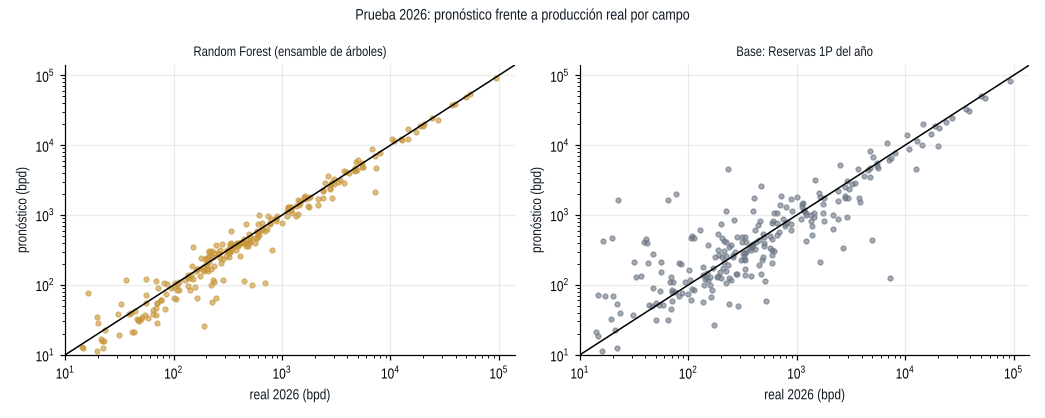

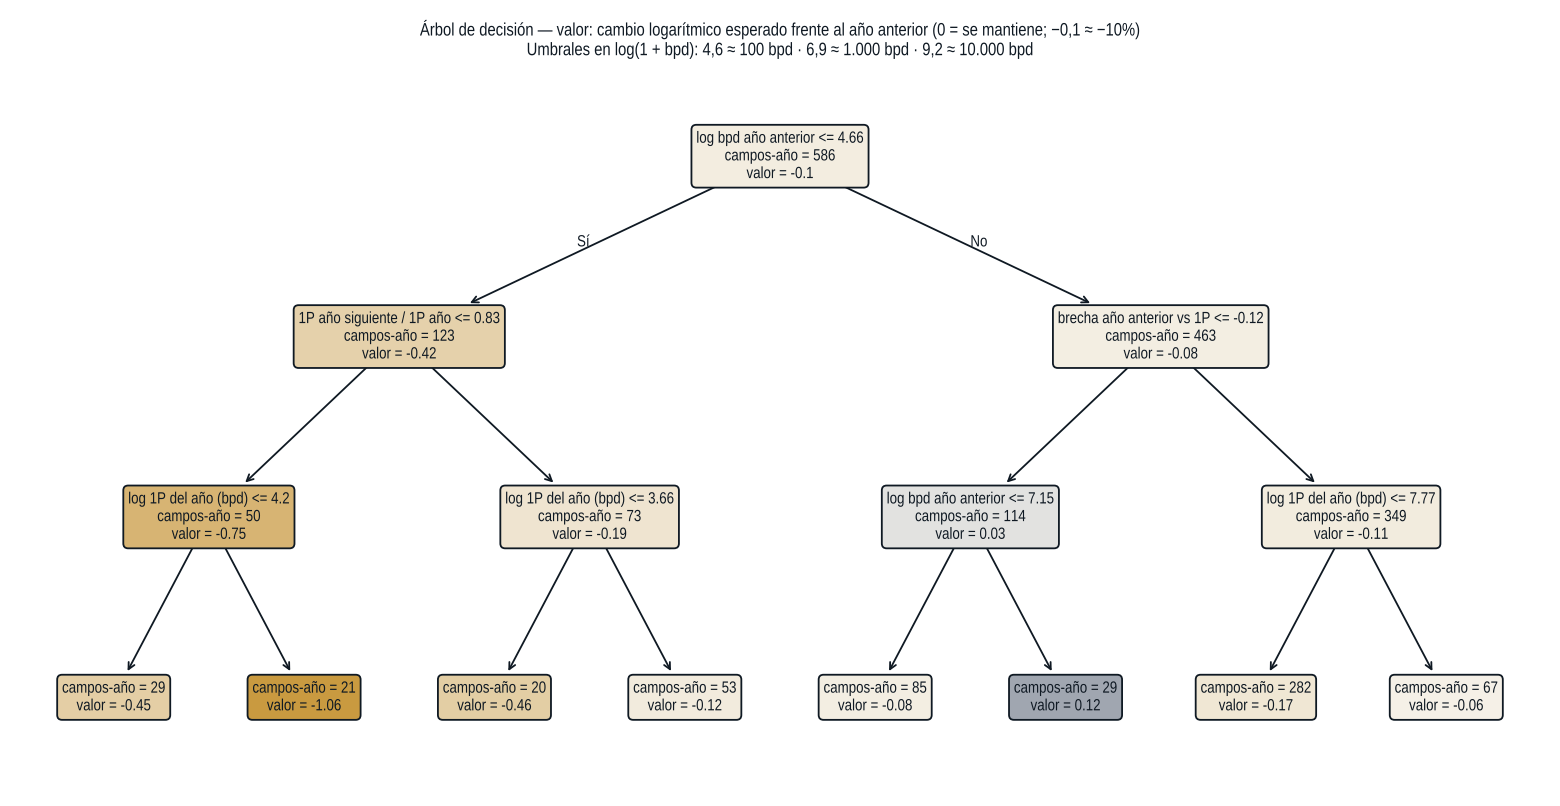

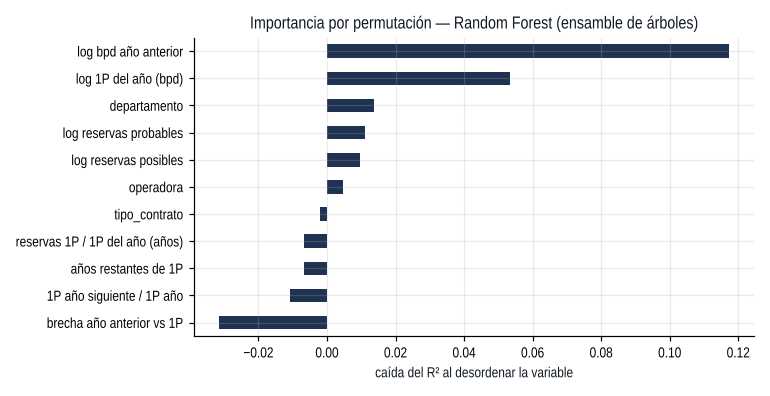

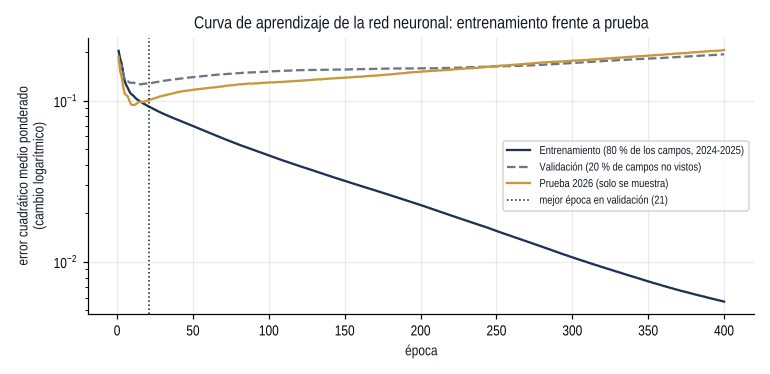

In [10]:
from IPython.display import Image, display
display(Image(filename=str(FIG / "prueba_real_vs_pronostico.png")))
display(Image(filename=str(FIG / "arbol_decision.png")))
display(Image(filename=str(FIG / "importancia_variables.png")))
display(Image(filename=str(FIG / "red_neuronal_aprendizaje.png")))

**Curva de aprendizaje de la red neuronal.** Compara, época a época, el error en entrenamiento, en validación (campos no vistos, que fija la
mejor época) y en la prueba 2026 (solo informativa). **Informe del mejor modelo:** la última salida de la celda resume el mejor modelo de cada familia
(árboles de decisión, regresión lineal y redes neuronales) y el mejor modelo global.

### 5.2 Umbral recomendado: alerta de bajo cumplimiento de la 1P

In [11]:
# ---- Umbral recomendado: alerta de "bajo cumplimiento" (producción < 90% de la 1P del año)
# Puntaje = cumplimiento pronosticado (pronóstico / 1P). El umbral se elige en la validación temporal (2025),
# minimizando un costo en el que NO alertar un incumplimiento real (regalías sobreestimadas) cuesta 3 veces una falsa alarma.
COSTO_FN, COSTO_FP, META = 3, 1, 0.90
m24 = ajustar(mejores[FINAL], tr24)
s_val = m24.bpd(va25[NUM + CAT]) / va25["r1p_bpd"].to_numpy(); y_val = (va25["bpd_real"] / va25["r1p_bpd"] < META).astype(int).to_numpy()
umbrales = np.round(np.arange(0.70, 1.21, 0.01), 2)
costos = [COSTO_FN * ((s_val >= u) & (y_val == 1)).sum() + COSTO_FP * ((s_val < u) & (y_val == 0)).sum() for u in umbrales]
U = float(umbrales[int(np.argmin(costos))])
s_test = pred_test[FINAL] / TEST["r1p_bpd"].to_numpy(); y_test = (TEST["bpd_real"] / TEST["r1p_bpd"] < META).astype(int).to_numpy()
def eval_umbral(s, y, u):
    a = (s < u).astype(int)
    return {"umbral": u, "AUC": roc_auc_score(y, -s), "sensibilidad": recall_score(y, a), "precisión": precision_score(y, a),
            "alertas": int(a.sum()), "incumplimientos reales": int(y.sum()), "costo medio": (COSTO_FN * ((a == 0) & (y == 1)).sum() + COSTO_FP * ((a == 1) & (y == 0)).sum()) / len(y)}
umbral_tab = pd.DataFrame([{"conjunto": "Validación 2025 (elección)", **eval_umbral(s_val, y_val, U)},
                           {"conjunto": "Prueba 2026", **eval_umbral(s_test, y_test, U)},
                           {"conjunto": "Prueba 2026 con umbral ingenuo 0,90", **eval_umbral(s_test, y_test, 0.90)}])
umbral_tab.to_csv(ART / "umbral_alerta.csv", index=False); print(umbral_tab.round(3).to_string(index=False))
ape = np.abs(m24.bpd(va25[NUM + CAT]) - va25["bpd_real"].to_numpy()) / va25["bpd_real"].to_numpy()
BANDA = float(np.median(ape))                      # error porcentual mediano por campo (validación 2025)
print(f"Umbral recomendado: alertar si cumplimiento pronosticado < {U:.2f}. Error mediano por campo (validación): ±{BANDA:.0%}")
pd.DataFrame({"umbral": umbrales, "costo_medio": np.array(costos) / len(y_val)}).to_csv(ART / "umbral_costos.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(umbrales, np.array(costos) / len(y_val), color=AZUL); ax.axvline(U, color=NARANJA, ls="--")
ax.set_xlabel("umbral de cumplimiento pronosticado"); ax.set_ylabel("costo medio por campo"); ax.set_title("Elección del umbral de alerta (validación 2025)")
fig.tight_layout(); fig.savefig(FIG / "umbral_costo.png"); plt.close(fig)

                           conjunto  umbral   AUC  sensibilidad  precisión  alertas  incumplimientos reales  costo medio
         Validación 2025 (elección)     1.0 0.837         0.880      0.615      179                     125        0.401
                        Prueba 2026     1.0 0.929         0.942      0.693      140                     103        0.237
Prueba 2026 con umbral ingenuo 0,90     0.9 0.929         0.845      0.829      105                     103        0.257
Umbral recomendado: alertar si cumplimiento pronosticado < 1.00. Error mediano por campo (validación): ±15%


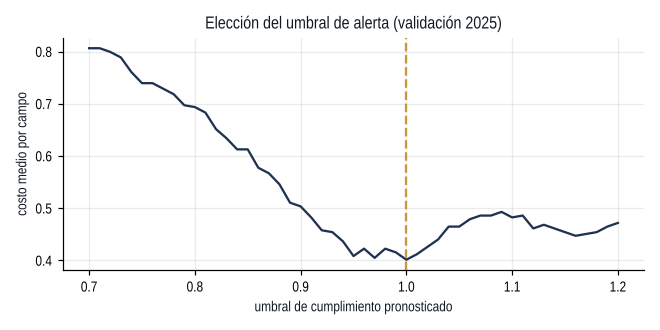

In [12]:
from IPython.display import Image, display
display(Image(filename=str(FIG / "umbral_costo.png")))

### 5.3 Estructura latente: segmentos de campos (no supervisado)

In [13]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ---- Estructura latente: ¿qué tipos de campos hay según su producción y su perfil 1P?
c1p = R1P.index[(BPD.reindex(R1P.index)[2025] > 0) & (R1P[2025] > 0)]
perf = pd.DataFrame(index=c1p)
perf["tamaño (log10 bpd 2025)"] = np.log10(BPD.loc[c1p, 2025])
perf["cambio 2025 vs 2024 (log)"] = np.log(BPD.loc[c1p, 2025] / BPD.reindex(c1p)[2024]).fillna(0).clip(-2, 2)
perf["cumplimiento 1P 2025"] = (BPD.loc[c1p, 2025] / R1P_BPD.loc[c1p, 2025]).clip(0, 3)
perf["declive 1P 2026-2030 (log)"] = np.log((R1P.loc[c1p, 2030] + 1) / (R1P.loc[c1p, 2026] + 1))
perf["años restantes de 1P"] = (campos.set_index("campo").loc[c1p, "ultimo_anio_1p"] - 2025).clip(lower=0)
perf["probables / 1P (2026-2030)"] = (PRB.reindex(c1p).loc[:, 2026:2030].fillna(0).sum(1) / R1P.loc[c1p, 2026:2030].sum(1).replace(0, np.nan)).fillna(0).clip(0, 3)
Z = StandardScaler().fit_transform(perf)
sil = pd.DataFrame([{"k": k, "silueta K-medias": silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)),
                     "silueta jerárquico (Ward)": silhouette_score(Z, AgglomerativeClustering(k).fit_predict(Z))} for k in range(2, 8)])
K = int(sil[sil.k.between(3, 6)].sort_values("silueta K-medias", ascending=False).iloc[0]["k"])
perf["segmento"] = KMeans(K, n_init=50, random_state=SEED).fit_predict(Z)
perfil = perf.groupby("segmento").median(); perfil["campos"] = perf.groupby("segmento").size()
zc = (perfil.drop(columns="campos") - perf.drop(columns="segmento").median()) / perf.drop(columns="segmento").std()
def nombre(z):
    p = ["Grandes" if z.iloc[0] > 0.5 else "Pequeños" if z.iloc[0] < -0.5 else "Medianos"]
    if z["cumplimiento 1P 2025"] > 0.5: p.append("por encima de su 1P")
    elif z["cumplimiento 1P 2025"] < -0.5: p.append("por debajo de su 1P")
    if z["años restantes de 1P"] > 0.5: p.append("de vida 1P larga")
    elif z["años restantes de 1P"] < -0.5: p.append("de vida 1P corta")
    if z["cambio 2025 vs 2024 (log)"] < -0.5: p.append("en declive")
    if z["probables / 1P (2026-2030)"] > 0.5: p.append("con potencial probable")
    return " ".join(p)
perfil["nombre"] = [f"S{i + 1}: {nombre(zc.loc[i])}" for i in perfil.index]
perf["nombre_segmento"] = perf["segmento"].map(perfil["nombre"])
pca = PCA(2, random_state=SEED).fit(Z)
# Convención de signo (el signo de un componente es arbitrario): C1 crece con el tamaño del campo y C2 con los años restantes de 1P
for j, ancla in ((0, 0), (1, 4)):
    if pca.components_[j, ancla] < 0: pca.components_[j] *= -1
perf[["pc1", "pc2"]] = pca.transform(Z)
cargas = pd.DataFrame(pca.components_.T, index=perf.columns[:6], columns=["componente_1", "componente_2"])
cargas.loc["varianza explicada"] = pca.explained_variance_ratio_; cargas.rename_axis("variable").to_csv(ART / "componentes_pca.csv")
print("Cargas de los componentes principales (variables estandarizadas):\n", cargas.round(2))
perf.rename_axis("campo").reset_index().to_csv(ART / "segmentos_campos.csv", index=False)
perfil.to_csv(ART / "perfil_segmentos.csv"); sil.to_csv(ART / "silueta.csv", index=False)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for s, g in perf.groupby("nombre_segmento"):
    ax.scatter(g.pc1, g.pc2, s=8 + 12 * g.iloc[:, 0].clip(0), alpha=.7, label=f"{s} ({len(g)})")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(fontsize=7); ax.set_title(f"Segmentos de campos (K-medias, k = {K})"); fig.tight_layout(); fig.savefig(FIG / "segmentos.png"); plt.close(fig)
print(sil.round(3).to_string(index=False)); perfil.round(2)

Cargas de los componentes principales (variables estandarizadas):
                             componente_1  componente_2
tamaño (log10 bpd 2025)             0.55         -0.11
cambio 2025 vs 2024 (log)           0.53         -0.24
cumplimiento 1P 2025                0.39         -0.51
declive 1P 2026-2030 (log)          0.34          0.56
años restantes de 1P                0.31          0.60
probables / 1P (2026-2030)         -0.26         -0.05
varianza explicada                  0.35          0.26


 k  silueta K-medias  silueta jerárquico (Ward)
 2             0.302                      0.250
 3             0.317                      0.280
 4             0.326                      0.305
 5             0.329                      0.329
 6             0.300                      0.285
 7             0.279                      0.274


,tamaño (log10 bpd 2025),cambio 2025 vs 2024 (log),cumplimiento 1P 2025,declive 1P 2026-2030 (log),años restantes de 1P,probables / 1P (2026-2030),campos,nombre
segmento,,,,,,,,
0,3.51,-0.04,0.94,-0.52,14.0,0.23,50,S1: Grandes de vida 1P larga
1,2.36,-0.17,0.94,-11.10,3.0,0.22,76,S2: Medianos de vida 1P corta
2,2.13,-0.15,0.89,-9.00,4.0,3.00,21,S3: Medianos con potencial probable
3,1.07,-1.59,0.13,-1.30,5.0,0.49,19,S4: Pequeños por debajo de su 1P en declive
4,2.57,-0.08,1.00,-0.71,7.0,0.15,121,S5: Medianos


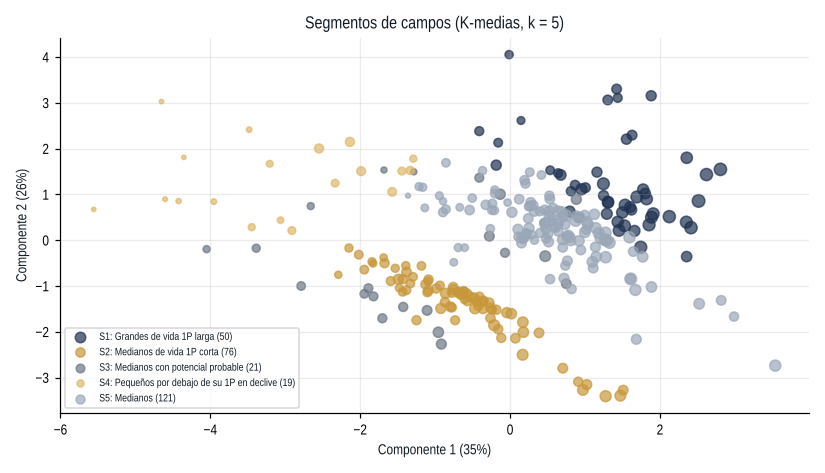

In [14]:
from IPython.display import Image, display
display(Image(filename=str(FIG / "segmentos.png")))

## 6. Despliegue: pronóstico 2026-2060, regalías y artefactos para el aplicativo
El modelo final se reentrena con 2024-2026 y pronostica año a año. 2026 = real enero-junio + pronóstico julio-diciembre. Desde 2027 solo se
pronostican campos con Reservas 1P en el año y el resultado nunca supera la 1P. Regalías: escala de la Ley 756 de 2002 según los barriles por día
del campo; en USD, por el precio promedio anual WTI o Brent (en el aplicativo).

In [15]:
# ---- Pronóstico 2026-2060 con el modelo final reentrenado con 2024-2026 (todo lo observado)
modelo_prod = ajustar(mejores[FINAL], DS)
H1_26 = prod.query("anio == 2026").set_index("campo")["prod_bl"]          # producción real enero-junio 2026
todos = campos["campo"]
bpd_ant = BPD.get(2025, pd.Series(dtype=float)).reindex(todos).fillna(0)  # bpd del año previo para la recursión
filas, metodo = [], {}
for t in range(2026, 2061):
    pron = pd.Series(np.nan, index=todos); como = pd.Series("", index=todos)
    con1p = R1P.reindex(todos)[t].fillna(0) > 0 if t in R1P.columns else pd.Series(False, index=todos)
    hist = bpd_ant > 0
    idx_m = todos[con1p.values & hist.values]
    if len(idx_m):
        pron.loc[idx_m] = modelo_prod.bpd(variables(idx_m, t, bpd_ant)[NUM + CAT]); como.loc[idx_m] = "Modelo ML"
    idx_p = todos[con1p.values & ~hist.values]                               # 1P sin historia: se usa el perfil 1P
    pron.loc[idx_p] = R1P_BPD.reindex(idx_p)[t]; como.loc[idx_p] = "Perfil 1P (sin historia productiva)"
    if t == 2026:
        sin1p = todos[~con1p.values & H1_26.reindex(todos).fillna(0).gt(0).values]   # campos sin 1P: persistencia del semestre
        pron.loc[sin1p] = H1_26.reindex(sin1p) / 181; como.loc[sin1p] = "Persistencia ene-jun (campo sin 1P)"
        cerrado = H1_26.reindex(todos).fillna(0).eq(0)                       # sin reporte en ene-jun 2026: no se asume segundo semestre
        pron[cerrado.values] = 0.0; como[cerrado.values & con1p.values] = "Sin reporte en ene-jun 2026: segundo semestre en cero"
        prod_pron = pron.fillna(0) * 184                                     # segundo semestre (184 días)
        prod_real = H1_26.reindex(todos).fillna(0)
        total = prod_real + prod_pron
    else:
        cap = R1P_BPD.reindex(todos)[t].fillna(0) if t in R1P_BPD.columns else pd.Series(0.0, index=todos)
        pron = np.minimum(pron, cap).where(con1p)                            # regla de negocio: nunca por encima de la 1P del año
        prod_real = pd.Series(np.nan, index=todos); prod_pron = pron * 365; total = prod_pron
        como = como.where(con1p, "Sin Reservas 1P en el año: no se pronostica")
    filas.append(pd.DataFrame({"campo": todos.values, "anio": t, "prod_real_bl": prod_real.values, "prod_pron_bl": prod_pron.values,
                               "prod_total_bl": total.values, "metodo": como.values}))
    bpd_ant = (total / 365).fillna(0)
fut = pd.concat(filas)
hist_ = prod[prod.anio <= 2025].rename(columns={"prod_bl": "prod_real_bl"})[["campo", "anio", "prod_real_bl"]]
hist_ = hist_.assign(prod_pron_bl=np.nan, prod_total_bl=hist_["prod_real_bl"], metodo="Dato real")
hechos = pd.concat([hist_, fut], ignore_index=True)
hechos = hechos.merge(r1p, on=["campo", "anio"], how="left").merge(campos, on="campo", how="left")
hechos["dias"] = hechos["anio"].map(lambda a: 366 if a == 2024 else 365)
hechos["bpd"] = hechos["prod_total_bl"] / hechos["dias"]
hechos["estado"] = np.select([hechos.anio <= 2025, hechos.anio == 2026], ["Real", "Real ene-jun + pronóstico jul-dic"], "Pronóstico (tope 1P)")
assert (hechos.query("anio >= 2027").prod_total_bl.fillna(0) <= hechos.query("anio >= 2027").r1p_bl.fillna(0) + 1e-6).all()

# ---- Regalías (Ley 756 de 2002, art. 16): porcentaje escalonado según la producción diaria promedio del campo (KBPD)
def tasa_ley756(bpd):
    k = np.asarray(bpd, float) / 1000
    return np.select([k <= 5, k <= 125, k <= 400, k <= 600], [0.08, 0.08 + (k - 5) * 0.001, 0.20, 0.20 + (k - 400) * 0.00025], 0.25)
hechos["tasa_regalia_1p"] = tasa_ley756(hechos["r1p_bl"].fillna(0) / hechos["dias"])
hechos["tasa_regalia_prod"] = tasa_ley756(hechos["bpd"].fillna(0))
hechos["regalias_1p_bl"] = hechos["r1p_bl"].fillna(0) * hechos["tasa_regalia_1p"]
hechos["regalias_prod_bl"] = hechos["prod_total_bl"].fillna(0) * hechos["tasa_regalia_prod"]
hechos.to_csv(ART / "hechos_campo_anio.csv", index=False)
res_nac = hechos.groupby("anio")[["prod_real_bl", "prod_pron_bl", "prod_total_bl", "r1p_bl", "regalias_1p_bl", "regalias_prod_bl"]].sum()
res_nac["bpd"] = res_nac["prod_total_bl"] / [366 if a == 2024 else 365 for a in res_nac.index]
res_nac.to_csv(ART / "resumen_nacional.csv")
fig, ax = plt.subplots(figsize=(8.5, 3.5))
d_ = np.array([366 if a == 2024 else 365 for a in res_nac.index])
ax.bar(res_nac.index, res_nac.prod_real_bl / d_ / 1e3, color=AZUL, label="Real")
ax.bar(res_nac.index, res_nac.prod_pron_bl / d_ / 1e3, bottom=res_nac.prod_real_bl / d_ / 1e3, color=NARANJA, label=f"Pronóstico ({FINAL}, tope 1P)")
ax.plot(res_nac.index[res_nac.index >= 2024], (res_nac.r1p_bl / d_ / 1e3)[res_nac.index >= 2024], color="k", ls=":", label="Reservas 1P (kbpd)")
ax.set_ylabel("miles de barriles por día"); ax.legend(fontsize=8); ax.set_title("Producción nacional: real 2023-2026 y pronóstico 2026-2060")
fig.tight_layout(); fig.savefig(FIG / "trayectoria_nacional.png"); plt.close(fig)
print((res_nac.loc[[2023, 2024, 2025, 2026, 2027, 2030, 2035, 2040]] / 1e6).round(2))

      prod_real_bl  prod_pron_bl  prod_total_bl  r1p_bl  regalias_1p_bl  \
anio                                                                      
2023        283.30          0.00         283.30    0.00            0.00   
2024        282.81          0.00         282.81  286.67           30.16   
2025        272.46          0.00         272.46  264.89           27.44   
2026        131.77        132.43         264.20  238.89           24.46   
2027          0.00        195.34         195.34  212.45           21.72   
2030          0.00        119.55         119.55  124.75           12.14   
2035          0.00         44.73          44.73   48.21            4.46   
2040          0.00         12.76          12.76   13.14            1.12   

      regalias_prod_bl   bpd  
anio                          
2023             30.18  0.78  
2024             29.82  0.77  
2025             28.80  0.75  
2026             27.87  0.72  
2027             20.23  0.54  
2030             11.73  0.33  
2

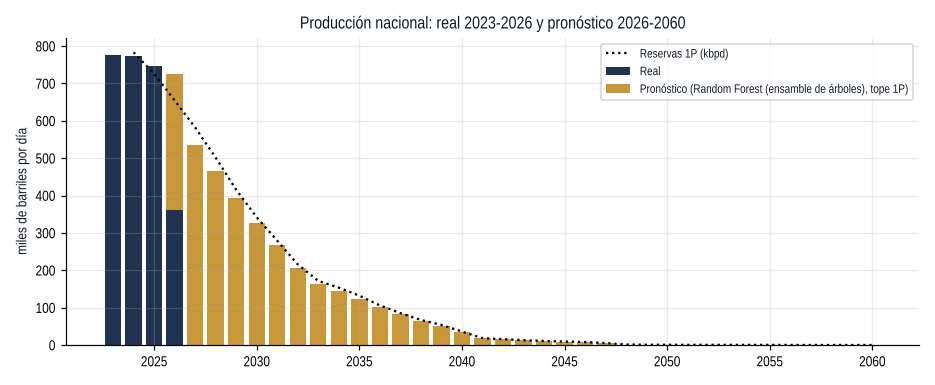

In [16]:
from IPython.display import Image, display
display(Image(filename=str(FIG / "trayectoria_nacional.png")))

In [17]:
# ---- Metadatos para el aplicativo y ficha de datos
fila_final = tabla.set_index("modelo").loc[FINAL]
meta = {"modelo_final": FINAL, "hiperparametros": fila_final["hiperparámetros"], "cv_wape": float(fila_final["CV WAPE"]),
        "cv_wape_desv": float(fila_final["CV WAPE desv."]), "prueba_wape": float(fila_final["Prueba WAPE"]),
        "prueba_sesgo": float(fila_final["Prueba Sesgo total"]), "error_mediano_campo": BANDA, "umbral_alerta": U, "meta_cumplimiento": META,
        "segmentos_k": K, "red_mejor_epoca": MEJOR_EPOCA, "pca_varianza": [float(v) for v in pca.explained_variance_ratio_], "diferencial_brent_wti": DIF, "versiones": VERSIONES, "fecha_corte": "2026-06 (producción real)",
        "filas_entrenamiento": {str(k): int(v) for k, v in DS.anio.value_counts().sort_index().items()}}
(ART / "metadatos.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
import joblib; joblib.dump({"modelo": modelo_prod, "variables": NUM + CAT}, ART / "modelo_final.joblib")

def ficha_tabla(df):
    t = pd.DataFrame({"tipo": df.dtypes.astype(str), "faltantes": df.isna().sum(), "%": (df.isna().mean() * 100).round(1)})
    return "\n".join(["| Columna | Tipo | Faltantes | % faltantes |", "|---|---|---|---|"] +
                     [f"| {i} | {r.tipo} | {r.faltantes} | {r['%']} |" for i, r in t.iterrows()])
cols_prin = list(crudo.columns[:7]) + [c for c in crudo.columns if c.endswith(("2023", "2024", "2025", "2026"))]
md = f"""# Ficha de datos — PFI: producción, Reservas 1P y regalías de petróleo en Colombia

Generada por `cuaderno_PFI.ipynb` el {pd.Timestamp.now():%Y-%m-%d}.

## 1. Archivo principal: `datos_crudos/1_ML_OIL_produccion_reservas.xlsx`

- **Fuente o portal:** Agencia Nacional de Hidrocarburos (ANH) y Ministerio de Minas y Energía (MME). Producción fiscalizada de petróleo por campo
  (2023 a junio de 2026) y pronóstico de Reservas Probadas (1P), Probables y Posibles por campo con base en el Informe de Recursos y Reservas (IRR) 2024
  (corte al 31 de diciembre de 2023); consolidado por el equipo en un solo libro. Portal: https://www.anh.gov.co/
- **Licencia o autorización:** datos de carácter reservado, con un único uso académico en el marco de la Especialización en Machine Learning
  de la Universidad EAN (2026). Está prohibido el uso, la distribución, la copia o la mejora, total o parcial, de los datos y de sus resultados.
- **Anonimización:** los nombres de los campos (Campo_001 a Campo_397) y de los contratos (Contrato_001 a Contrato_135) están anonimizados
  porque el repositorio es público; la numeración sigue el orden alfabético original. Operadoras, departamentos y municipios se conservan.
- **Alcance:** solo se tiene en cuenta el pronóstico de desarrollo de reservas del IRR 2024; no se contempla la migración de reservas probables (2P)
  y posibles (3P) a probadas ni la evolución de los recursos contingentes.
- **Fecha de acceso:** 2026-10-16.
- **Hojas:** `1P_Oil_final_val_col_abr29 2024` ({len(crudo)} filas × {crudo.shape[1]} columnas), `Petróleo_1P Pronóstico` ({len(p1)} filas),
  `Petróleo_Prb` ({len(prb)} filas), `Petróleo_Ps` ({len(ps)} filas). Las columnas de 2027 a 2060 de "Producción Bls" son fórmulas iguales a la 1P y
  no se usan como dato observado.
- **Unidad:** barriles (bl) por año; barriles por día (bpd). La producción 2026 cubre enero a junio (181 días).
- **Población:** {int(campos.con_1p.sum())} campos con Reservas 1P y {int((~campos.con_1p).sum())} campos con producción sin 1P.
- **Cita (APA 7):** Agencia Nacional de Hidrocarburos & Ministerio de Minas y Energía. (2026). *Producción fiscalizada y pronóstico de reservas 1P,
  2P y 3P de petróleo por campo, 2023–2060* [Conjunto de datos]. https://www.anh.gov.co/

### Faltantes por columna (hoja principal, columnas observadas)

{ficha_tabla(crudo[cols_prin])}

### Hojas de reservas (columnas de identificación y años 2024-2030)

{ficha_tabla(pd.concat([p1[['OPERADOR', 'CONTRATO', 'CAMPO', 'ACTIVIDAD'] + list(range(2024, 2031))].add_prefix('1P · '),
                       prb[['CAMPO'] + list(range(2024, 2031))].add_prefix('Prb · '), ps[['CAMPO'] + list(range(2024, 2031))].add_prefix('Ps · ')], axis=1))}

## 2. Precios: `datos_crudos/precios_brent_wti_mensual_EIA.csv`

- **Fuente o portal:** U.S. Energy Information Administration (EIA), precios spot mensuales Europe Brent (RBRTE) y WTI Cushing (RWTC); para 2027,
  Short-Term Energy Outlook del 6 de octubre de 2026. Son las mismas referencias que publica investing.com (que no permite descargar promedios anuales).
- **Licencia:** dominio público (datos del Gobierno de EE. UU.).
- **Fecha de acceso:** 2026-10-16. **Filas:** {len(pm)} · **Columnas:** {pm.shape[1]} (anio, mes, brent_usd_bl, wti_usd_bl, fuente) · sin faltantes.
- **Cita (APA 7):** U.S. Energy Information Administration. (2026). *Europe Brent spot price FOB; Cushing, OK WTI spot price FOB* [Conjunto de datos].
  https://www.eia.gov/dnav/pet/pet_pri_spt_s1_m.htm
"""
(BASE / "ficha_datos.md").write_text(md, encoding="utf-8")
print("Artefactos:", sorted(p.name for p in ART.iterdir()))

Artefactos: ['arbol_reglas.txt', 'calidad_faltantes.csv', 'calidad_hallazgos.csv', 'coeficientes_numericos.csv', 'coeficientes_regresion_lineal.csv', 'comparacion_modelos.csv', 'componentes_pca.csv', 'curva_aprendizaje_red.csv', 'error_por_tamano.csv', 'figuras', 'hechos_campo_anio.csv', 'importancia_variables.csv', 'metadatos.json', 'modelo_final.joblib', 'perfil_segmentos.csv', 'precios_anuales.csv', 'prueba_predicciones.csv', 'resumen_nacional.csv', 'segmentos_campos.csv', 'silueta.csv', 'umbral_alerta.csv', 'umbral_costos.csv']


## 7. Cierre
Aplicativo: `streamlit run app/app.py` (o doble clic en `iniciar_app.command`) → http://localhost:8501. El informe, el resumen ejecutivo en inglés
y la guía explican los resultados y cada decisión.